# RetinaNet

## 1. Setup and training configuration

We compare one baseline and two independent modifications of COCO-pretrained RetinaNet
ResNet-50 FPN V2. RetinaNet predicts classes and boxes directly over feature-pyramid
anchors. Faster R-CNN first generates proposals and then processes RoIs. RetinaNet's
large foreground/background candidate imbalance motivates its focal classification loss.

Full RetinaNet with standard anchors, RetinaNet with smaller anchors, and RetinaNet with DIoU regression training is disabled. A separate smoke switch permits only six total
optimizer steps on four training and at most four validation frames. Diagnostic metrics
are never used as graded results. No test frames enter training or model selection.

In [1]:
import hashlib
import json
import logging
import platform
import sys
from io import BytesIO
from pathlib import Path

import numpy as np
import plotly.express as px
import polars as pl
import torch
import torchvision
from decouple import config
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display

working_directory = Path.cwd().resolve()
REPOSITORY_ROOT = next(
    directory
    for directory in (working_directory, *working_directory.parents)
    if (directory / "pyproject.toml").is_file() and (directory / "src/hm2").is_dir()
)
sys.path.insert(0, str(REPOSITORY_ROOT / "src"))

from hm2.data import CLASS_NAMES, find_dataset_root
from hm2.detection_data import DetectionDataset, make_loader, select_frames
from hm2.evaluation import evaluate_coco, predictions_to_coco
from hm2.experiment_checkpoint import load_checkpoint
from hm2.experiment_names import (
    describe_text,
    descriptive_name,
    experiment_label,
    result_directory,
    storage_id,
)
from hm2.retinanet import (
    build_retinanet,
    make_optimizer,
    predict_loader,
    run_smoke_test,
    train_steps,
)
from hm2.visualization import draw_prediction_pair

METADATA_DIRECTORY = REPOSITORY_ROOT / "data/metadata"
EXPERIMENT_DIRECTORY = REPOSITORY_ROOT / "data/experiments/retinanet"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
torch.backends.cudnn.benchmark = False
pl.Config.set_tbl_rows(12)
logging.basicConfig(level=logging.INFO, stream=sys.stdout)

runtime = {
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "TorchVision": torchvision.__version__,
    "Device": str(DEVICE),
    "CUDA build": torch.version.cuda,
    "GPU": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "Free VRAM GiB": torch.cuda.mem_get_info()[0] / 1024**3 if DEVICE.type == "cuda" else None,
}
pl.from_dicts([runtime])

Python,PyTorch,TorchVision,Device,CUDA build,GPU,Free VRAM GiB
str,str,str,str,null,null,null
"""3.14.8""","""2.15.0""","""0.29.2""","""cpu""",null,null,null


We use the locked Python 3.14 environment for local development. We validated the
pretrained execution path on a hosted Tesla T4 with Python 3.13.16, PyTorch
2.11.0+cu130 and TorchVision 0.26.0+cu130. We record the measured smoke summary below.
We retain the hosted runtime's compatible CUDA stack and reuse cached model weights
and the prepared dataset. The native Colab and Kaggle execution notebooks use the
shared setup and checkpoint utilities described in [AGENTS.md](../AGENTS.md#hosted-experiment-execution).

In [2]:
RUN_SMOKE_TEST = False
RUN_RECIPE_TIMING = False
RUN_GRADED_EXPERIMENTS = False
ALLOW_WEIGHT_DOWNLOAD = False

TRAINING = {
    "seed": 2026,
    "frame_stride": 8,
    "max_steps": 3000,
    "warmup_steps": 100,
    "learning_rate": 0.0025,
    "batch_size": 2,
    "num_workers": 2,
    "min_size": 640,
    "max_size": 1024,
    "flip_probability": 0.5,
}
SMOKE = {
    "steps_per_run": 2,
    "min_size": 320,
    "max_size": 512,
    "batch_size": 1,
    "num_workers": 2,
}
EXPERIMENTS = {
    "standard_anchors": {"anchor_scale": 1.0, "regression_loss": "GIoU"},
    "smaller_anchors": {"anchor_scale": 0.5, "regression_loss": "GIoU"},
    "diou_regression": {"anchor_scale": 1.0, "regression_loss": "DIoU"},
}
pl.from_dicts([{"Run": experiment_label(run), **settings} for run, settings in EXPERIMENTS.items()])

Run,anchor_scale,regression_loss
str,f64,str
"""RetinaNet with standard anchors""",1.0,"""GIoU"""
"""RetinaNet with smaller anchors""",0.5,"""GIoU"""
"""RetinaNet with DIoU regression""",1.0,"""DIoU"""


We use SGD with momentum 0.9 and weight decay 0.0001. This is a conventional pretrained
detector recipe and needs one momentum buffer per parameter. The shared schedule warms
up for 100 steps and reduces LR by 0.1 at steps 2000 and 2700. Fused AdamW is a supported
alternative, but changing the optimizer would add a fourth ablation without convergence
evidence. We do not add that experiment.

CUDA training uses fp16 autocast, gradient scaling, pinned memory, nonblocking transfers,
and `zero_grad(set_to_none=True)`. Two workers use persistent processes and prefetch two
batches each. The diagnostic compares decoding with zero and two workers. CPU mode uses
float32. Channels-last and compilation are not enabled without evidence that their setup
cost benefits this short workload. All three graded configurations share these choices.

## 2. Dataset and model contract checks

We reuse the prepared tables and original image paths. Each selected training clip
contributes every eighth available frame. This selection and the complete official
validation set are fixed across runs. Image decoding happens only when a batch is read.
Annotation tensors and lookups are built once, with no per-image DataFrame filtering.

The existing EDA reports 24,201 train frames in 56 clips and 2,846 validation frames in
7 separate clips. About 24.9% of train boxes are COCO-small, the median density is
43 targets per frame, and car contributes about 45.7% of train targets. Source frames
reach 3840 × 2160 pixels. The table below records the selected subset's distribution.

In [3]:
manifest = json.loads((METADATA_DIRECTORY / "manifest.json").read_text())
configured_root = config("HM2_DATA_DIR", default=None)
dataset_root = (
    find_dataset_root(Path(configured_root).expanduser())
    if configured_root
    else Path(manifest["dataset_root"])
)
if dataset_root is None or not dataset_root.is_dir():
    raise FileNotFoundError("Make the existing extracted data available and set HM2_DATA_DIR.")
for name, signature in manifest["sources"].items():
    stat = (dataset_root / name).stat()
    if (stat.st_size, stat.st_mtime_ns) != (signature["size"], signature["mtime_ns"]):
        raise ValueError(f"Source metadata changed: {name}. Rerun 00_data.ipynb.")
frames = pl.read_parquet(METADATA_DIRECTORY / "frames.parquet")
objects = pl.read_parquet(METADATA_DIRECTORY / "objects.parquet")
ignored_regions = pl.read_parquet(METADATA_DIRECTORY / "ignored_regions.parquet")
train_frames = select_frames(frames, "train", TRAINING["frame_stride"])
val_frames = select_frames(frames, "val")
train_objects = objects.join(train_frames.select("image_key"), on="image_key", how="semi")
overlap = set(train_frames["clip"]) & set(val_frames["clip"])
if overlap:
    raise ValueError("The selected train and validation clips overlap.")
pl.from_dicts(
    [
        {
            "Split": "Train selection",
            "Frames": train_frames.height,
            "Clips": train_frames["clip"].n_unique(),
        },
        {
            "Split": "Official validation",
            "Frames": val_frames.height,
            "Clips": val_frames["clip"].n_unique(),
        },
    ]
)

Split,Frames,Clips
str,i64,i64
"""Train selection""",3050,56
"""Official validation""",2846,7


In [4]:
selection_distribution = (
    train_objects.group_by("class_name")
    .agg(
        pl.len().alias("Annotations"),
        (pl.col("area") < 32**2).mean().alias("Small-object fraction"),
        pl.col("area").median().alias("Median source area px²"),
    )
    .with_columns((pl.col("Annotations") / pl.col("Annotations").sum()).alias("Class fraction"))
)
selection_distribution.sort("Annotations", descending=True)

class_name,Annotations,Small-object fraction,Median source area px²,Class fraction
str,u32,f64,f64,f64
"""car""",63666,0.163714,3250.0,0.456309
"""person""",41594,0.394913,1280.0,0.298114
"""motor""",12968,0.304365,1617.0,0.092945
"""van""",5922,0.213441,2485.0,0.042444
"""tricycle""",5220,0.209962,3010.0,0.037413
"""bicycle""",5098,0.24284,1724.0,0.036539
"""truck""",3837,0.094084,5396.0,0.027501
"""bus""",1219,0.041838,12928.0,0.008737


In [5]:
train_dataset = DetectionDataset(dataset_root, train_frames, objects, TRAINING["flip_probability"])
val_dataset = DetectionDataset(dataset_root, val_frames, objects)
sample_image, sample_target = val_dataset[0]
pl.DataFrame(
    {
        "Image key": [val_dataset.records[0]["image_key"]],
        "Shape": [list(sample_image.shape)],
        "Pixel range": [[float(sample_image.min()), float(sample_image.max())]],
        "Box shape": [list(sample_target["boxes"].shape)],
        "Foreground labels": [sample_target["labels"].unique().tolist()],
        "Original size": [sample_target["original_size"].tolist()],
    }
)

Image key,Shape,Pixel range,Box shape,Foreground labels,Original size
str,list[i64],list[f64],list[i64],list[i64],list[i64]
"""val/uav0000086_00000_v/0000001""","[3, 756, 1344]","[0.0, 1.0]","[36, 4]","[1, 8]","[756, 1344]"


Targets use float32 pixel `xyxy` boxes and int64 labels 1 to 8. The head has nine outputs
per anchor, with index 0 reserved and removed from reported predictions. Empty targets
remain valid. The split and clip stay in each image key, while evaluation uses the source
COCO image ID within the selected split. We do not apply external normalization or resize
before TorchVision's own transform. Validation outputs are returned to source pixels.

Ordinary GT is preserved even inside ignored regions. Evaluation reads the original
COCO JSON with all category-specific crowd records, not deduplicated display geometries.
Stock RetinaNet does not consume ignore-region masks when assigning negative anchors.
Consequently ignored areas can still contribute classification negatives during training.
This is an explicit shared limitation, not an ignore-aware training implementation.
Exact Kaggle custom-scoring overlap semantics remain unresolved.

## 3. Standard anchor baseline

We load the COCO detector before replacing its classification head with nine outputs per
anchor. The pretrained convolutional class tower, backbone, FPN, and box-regression head
are retained. The new class output layer is initialized with seed 2026 in every run.

The following lightweight inspection uses random initialization only to verify architecture
contracts without a weight download. It is not a pretrained smoke test or a graded run.

In [6]:
architecture = build_retinanet("standard_anchors", pretrained=False, min_size=64, max_size=96)
default_sizes = architecture.anchor_generator.sizes
default_ratios = architecture.anchor_generator.aspect_ratios
architecture_summary = {
    "Model": "RetinaNet ResNet-50 FPN V2",
    "Head classes": architecture.head.classification_head.num_classes,
    "Classification channels": architecture.head.classification_head.cls_logits.out_channels,
    "Anchors per location": architecture.anchor_generator.num_anchors_per_location(),
    "Regression loss": architecture.head.regression_head._loss_type,
    "Inspection initialization": "Random, architecture only",
}
pl.from_dicts([architecture_summary])

Model,Head classes,Classification channels,Anchors per location,Regression loss,Inspection initialization
str,i64,i64,list[i64],str,str
"""RetinaNet ResNet-50 FPN V2""",9,81,"[9, 9, … 9]","""giou""","""Random, architecture only"""


## 4. Smaller anchor scales

We halve each installed default anchor size, keeping five FPN levels, three scales and
three aspect ratios per level. Both heads still use nine anchors per spatial location.
We inspect box size after the shared model resize rather than selecting anchors from
source-image sizes alone. This projection approximates the transform's integer rounding.

**Hypothesis.** Smaller anchors may better cover small resized targets and improve
AP_small. They may also reduce coverage of large objects. This needs measured RetinaNet with smaller anchors results.

In [7]:
anchor_model = build_retinanet("smaller_anchors", pretrained=False, min_size=64, max_size=96)
anchor_table = pl.from_dicts(
    [
        {
            "FPN level": f"P{index + 3}",
            "Default sizes px": list(default),
            "Smaller sizes px": list(smaller),
            "Aspect ratios": list(ratios),
            "Anchors per location": 9,
        }
        for index, (default, smaller, ratios) in enumerate(
            zip(default_sizes, anchor_model.anchor_generator.sizes, default_ratios, strict=True)
        )
    ]
)
anchor_table

FPN level,Default sizes px,RetinaNet with smaller anchors sizes px,Aspect ratios,Anchors per location
str,list[i64],list[i64],list[f64],i64
"""P3""","[32, 40, 50]","[16, 20, 25]","[0.5, 1.0, 2.0]",9
"""P4""","[64, 80, 101]","[32, 40, 50]","[0.5, 1.0, 2.0]",9
"""P5""","[128, 161, 203]","[64, 80, 101]","[0.5, 1.0, 2.0]",9
"""P6""","[256, 322, 406]","[128, 161, 203]","[0.5, 1.0, 2.0]",9
"""P7""","[512, 645, 812]","[256, 322, 406]","[0.5, 1.0, 2.0]",9


In [8]:
resize_factors = train_frames.select(
    "image_key",
    pl.min_horizontal(
        TRAINING["min_size"] / pl.min_horizontal("image_width", "image_height"),
        TRAINING["max_size"] / pl.max_horizontal("image_width", "image_height"),
    ).alias("resize_scale"),
)
resized_boxes = train_objects.join(resize_factors, on="image_key").with_columns(
    (pl.col("width") * pl.col("resize_scale")).alias("resized_width"),
    (pl.col("height") * pl.col("resize_scale")).alias("resized_height"),
    (pl.col("area").sqrt() * pl.col("resize_scale")).alias("resized_side"),
)
resized_boxes.select(
    pl.col("resized_side").quantile(0.1).alias("Square-root area p10 px"),
    pl.col("resized_side").median().alias("Median square-root area px"),
    pl.col("resized_side").quantile(0.9).alias("Square-root area p90 px"),
    pl.col("resized_width").median().alias("Median width px"),
    pl.col("resized_height").median().alias("Median height px"),
)

Square-root area p10 px,Median square-root area px,Square-root area p90 px,Median width px,Median height px
f64,f64,f64,f64,f64
12.862433,24.291151,53.049585,23.663866,25.277311


## 5. DIoU regression loss

RetinaNet with DIoU regression replaces only GIoU box regression with DIoU. Focal classification loss and the default
anchors stay unchanged. The internal `_loss_type` change is localized, version checked,
and exercised by a real forward, backward, optimizer, and resume unit test.

**Hypothesis.** The DIoU center-distance term may change localization behavior on small
or crowded targets. No improvement is claimed before the controlled experiment runs.

In [9]:
loss_model = build_retinanet("diou_regression", pretrained=False, min_size=64, max_size=96)
pl.from_dicts(
    [
        {
            "Run": experiment_label("standard_anchors"),
            "Regression loss": architecture.head.regression_head._loss_type,
        },
        {
            "Run": experiment_label("smaller_anchors"),
            "Regression loss": anchor_model.head.regression_head._loss_type,
        },
        {
            "Run": experiment_label("diou_regression"),
            "Regression loss": loss_model.head.regression_head._loss_type,
        },
    ]
)

Run,Regression loss
str,str
"""RetinaNet with standard anchors""","""giou"""
"""RetinaNet with smaller anchors""","""giou"""
"""RetinaNet with DIoU regression""","""diou"""


### Short GPU smoke test

We enable `RUN_SMOKE_TEST` on a CUDA kernel and cache the official pretrained weights.
We use the same
dataset, model, training, inference, and evaluator path used by the graded configurations.
Two optimizer updates per run give six total, with at most three attempts per run.
Skipped AMP updates do not consume the optimization budget. Four real train frames are fixed by seed.
Validation examples include a dense frame and a frame with tiny objects where available.

The smaller 320/512 resize and batch size 1 apply to every diagnostic run. They are not
graded settings. Step 1 is warmup for timing, leaving one measured training step per run.
Loader timings also use only a few images, so startup overhead and noise are substantial.

In [10]:
smoke_train = train_frames.sample(n=min(4, train_frames.height), seed=TRAINING["seed"])
val_min_areas = (
    objects.filter(pl.col("split") == "val")
    .group_by("image_key")
    .agg(pl.col("area").min().alias("min_area"))
)
smoke_val = (
    pl.concat(
        [
            val_frames.sort("target_count", descending=True).head(1),
            val_frames.join(val_min_areas, on="image_key")
            .sort("min_area")
            .head(1)
            .select(val_frames.columns),
            val_frames.sample(n=min(2, val_frames.height), seed=TRAINING["seed"]),
        ]
    )
    .unique("image_key", maintain_order=True)
    .head(4)
)
if RUN_SMOKE_TEST:
    smoke_summary = run_smoke_test(
        dataset_root,
        smoke_train,
        smoke_val,
        objects,
        TRAINING,
        SMOKE,
        EXPERIMENT_DIRECTORY / "smoke",
        allow_download=ALLOW_WEIGHT_DOWNLOAD,
    )
else:
    smoke_path = EXPERIMENT_DIRECTORY / "smoke/smoke_summary.json"
    smoke_summary = json.loads(smoke_path.read_text()) if smoke_path.is_file() else None
smoke_rows = (
    [
        {
            "Run": experiment_label(result["run"]),
            "Status": result["status"],
            "Optimizer steps": result["optimizer_updates"],
            "Peak allocated GiB": result["peak_allocated_gib"],
            "Peak reserved GiB": result["peak_reserved_gib"],
            "Train images/s": result["training_images_per_second"],
            "Validation ms/frame": result["inference"]["milliseconds_per_frame"],
        }
        for result in smoke_summary["runs"]
    ]
    if smoke_summary
    else [{"Status": "GPU model smoke not run. Device probe alone is not a training test."}]
)
pl.from_dicts(smoke_rows)

Run,Status,Optimizer steps,Peak allocated GiB,Peak reserved GiB,Train images/s,Validation ms/frame
str,str,i64,f64,f64,f64,f64
"""RetinaNet with standard anchors""","""Diagnostic only""",2,0.692302,1.078125,7.679362,135.791916
"""RetinaNet with smaller anchors""","""Diagnostic only""",2,0.692302,1.078125,12.749827,150.173081
"""RetinaNet with DIoU regression""","""Diagnostic only""",2,0.692302,1.078125,12.063229,175.464138


The CLI smoke completed all six requested updates and evaluated four validation images
for every variant. Those tiny-subset metrics are diagnostic only. The class output layer
is newly initialized, so these few steps are not evidence of useful detection quality.
The zero-worker and two-worker decode timings include only three measured frames after
startup. They cannot establish a general throughput improvement or rank the models.

Two additional RetinaNet with standard anchors diagnostic updates use the actual shared 640/1024 resize and batch size
2. We measure eight diagnostic optimizer updates in total. The first
attempt is timing warmup. The saved estimate below uses the remaining measured batch and
excludes validation, checkpoints, and AMP retries. It is a noisy budget estimate from four
source frames, not a full training measurement or a timed RetinaNet with smaller anchors/RetinaNet with DIoU regression comparison.

In [11]:
recipe_probe_path = EXPERIMENT_DIRECTORY / "smoke/recipe_probe.json"
if RUN_RECIPE_TIMING:
    if DEVICE.type != "cuda":
        raise RuntimeError("Use an authorized CUDA kernel for the two-update recipe timing.")
    probe_model = build_retinanet(
        "standard_anchors",
        allow_download=ALLOW_WEIGHT_DOWNLOAD,
        min_size=TRAINING["min_size"],
        max_size=TRAINING["max_size"],
        seed=TRAINING["seed"],
    ).to(DEVICE)
    probe_optimizer, probe_scheduler = make_optimizer(
        probe_model, TRAINING["learning_rate"], TRAINING["max_steps"], TRAINING["warmup_steps"]
    )
    probe_dataset = DetectionDataset(
        dataset_root, smoke_train, objects, TRAINING["flip_probability"]
    )
    probe_loader = make_loader(
        probe_dataset,
        TRAINING["batch_size"],
        TRAINING["num_workers"],
        DEVICE,
        should_shuffle=True,
        seed=TRAINING["seed"],
    )
    torch.cuda.reset_peak_memory_stats(DEVICE)
    probe_history = train_steps(
        probe_model, probe_loader, probe_optimizer, probe_scheduler, DEVICE, 2, max_attempts=4
    )
    probe_measured = probe_history[1:]
    probe_throughput = (
        len(probe_measured) * TRAINING["batch_size"] / sum(row["seconds"] for row in probe_measured)
    )
    probe_record = {
        "status": "Diagnostic only, standard-anchor recipe timing, not a graded experiment",
        "run": "standard_anchors",
        "device": torch.cuda.get_device_name(DEVICE),
        "training_config": TRAINING,
        "history": probe_history,
        "warmup_attempts": 1,
        "measured_attempts": len(probe_measured),
        "optimizer_updates": sum(row["optimizer_updated"] for row in probe_history),
        "training_images_per_second": probe_throughput,
        "peak_allocated_gib": torch.cuda.max_memory_allocated(DEVICE) / 1024**3,
        "peak_reserved_gib": torch.cuda.max_memory_reserved(DEVICE) / 1024**3,
        "estimated_training_minutes_per_run": TRAINING["max_steps"]
        * TRAINING["batch_size"]
        / probe_throughput
        / 60,
        "estimate_limitations": "One measured batch after warmup. Excludes validation, checkpoints, and AMP retries. Standard anchors only, noisy four-frame diagnostic.",
    }
    recipe_probe_path.parent.mkdir(parents=True, exist_ok=True)
    recipe_probe_path.write_text(json.dumps(probe_record, indent=2) + "\n")
    del probe_model, probe_optimizer, probe_scheduler, probe_loader
    torch.cuda.empty_cache()
recipe_probe = json.loads(recipe_probe_path.read_text()) if recipe_probe_path.is_file() else None
pl.from_dicts(
    [
        {
            "Status": describe_text(recipe_probe["status"]),
            "Device": recipe_probe["device"],
            "Measured batches": recipe_probe["measured_attempts"],
            "Batch size": recipe_probe["training_config"]["batch_size"],
            "Train images/s": recipe_probe["training_images_per_second"],
            "Peak allocated GiB": recipe_probe["peak_allocated_gib"],
            "Peak reserved GiB": recipe_probe["peak_reserved_gib"],
            "Estimated train minutes/run": recipe_probe["estimated_training_minutes_per_run"],
        }
    ]
    if recipe_probe
    else [{"Status": "Recipe timing not run"}]
)

Status,Device,Measured batches,Batch size,Train images/s,Peak allocated GiB,Peak reserved GiB,Estimated train minutes/run
str,str,i64,i64,f64,f64,f64,f64
"""Diagnostic only, RetinaNet with standard anchors recipe tim…","""Tesla T4""",1,2,7.40241,1.711833,1.875,13.509114


### Graded runs, disabled by default

We keep these exploratory runs disabled by default and select their run IDs explicitly
when executing them on a GPU. All runs use the same selected train frames, complete
official validation, resize, augmentation, SGD schedule, seed, and 3000-step budget.

Checkpoints contain model, optimizer, schedule, AMP scaler, RNG states, completed step,
and the exact configuration. Resume continues the optimization budget. The data iterator
restarts on resume, and worker-prefetch/augmentation streams are not guaranteed to replay
bit for bit. CUDA kernels may also be nondeterministic. Record resumed runs explicitly.

In [12]:
validation_protocol = {
    "split": "val",
    "image_count": val_frames.height,
    "image_keys_sha256": hashlib.sha256(
        "\n".join(sorted(val_frames["image_key"])).encode()
    ).hexdigest(),
    "max_dets": [1, 10, 100],
    "category_ids": list(range(1, 9)),
    "iou_thresholds": np.linspace(0.5, 0.95, 10).tolist(),
    "coordinates": "original_image_pixels",
    "ignore_policy": "original_category_specific_crowds",
}
GRADED_RUN_IDS = ["standard_anchors", "smaller_anchors", "diou_regression"]
if RUN_GRADED_EXPERIMENTS:
    if DEVICE.type != "cuda":
        raise RuntimeError("Use an authorized CUDA kernel for full training.")
    for run in GRADED_RUN_IDS:
        run_directory = result_directory(EXPERIMENT_DIRECTORY, run)
        model = build_retinanet(
            run,
            allow_download=ALLOW_WEIGHT_DOWNLOAD,
            min_size=TRAINING["min_size"],
            max_size=TRAINING["max_size"],
            seed=TRAINING["seed"],
        ).to(DEVICE)
        optimizer, scheduler = make_optimizer(
            model, TRAINING["learning_rate"], TRAINING["max_steps"], TRAINING["warmup_steps"]
        )
        scaler = torch.amp.GradScaler("cuda")
        run_config = {
            "run": storage_id(run),
            "training": TRAINING,
            "variant": EXPERIMENTS[run],
            "validation_protocol": validation_protocol,
            "initialization": "COCO-pretrained",
            "model": "retinanet_resnet50_fpn_v2",
            "head_classes": 9,
            "optimizer": "SGD",
            "momentum": 0.9,
            "weight_decay": 0.0001,
            "amp": "CUDA fp16",
            "anchor_sizes": [list(level) for level in model.anchor_generator.sizes],
            "regression_loss": model.head.regression_head._loss_type,
            "torch": torch.__version__,
            "torchvision": torchvision.__version__,
            "gpu": torch.cuda.get_device_name(DEVICE),
        }
        start_step = 0
        checkpoint = run_directory / "latest.pt"
        if checkpoint.is_file():
            state = load_checkpoint(checkpoint, model, optimizer, scheduler, scaler)
            if state["config"] != run_config:
                raise ValueError("Checkpoint configuration differs from the requested run.")
            start_step = state["step"]
        loader = make_loader(
            train_dataset,
            TRAINING["batch_size"],
            TRAINING["num_workers"],
            DEVICE,
            should_shuffle=True,
            seed=TRAINING["seed"],
        )
        val_loader = make_loader(val_dataset, 1, TRAINING["num_workers"], DEVICE)
        history = train_steps(
            model,
            loader,
            optimizer,
            scheduler,
            DEVICE,
            TRAINING["max_steps"] - start_step,
            start_step=start_step,
            scaler=scaler,
            should_show_progress=True,
            checkpoint_path=checkpoint,
            config=run_config,
        )
        predictions, image_ids, speed = predict_loader(model, val_loader, DEVICE, warmup=2)
        records = predictions_to_coco(predictions, image_ids)
        metrics = evaluate_coco(dataset_root / "val/annotations_coco.json", records, image_ids)
        run_directory.mkdir(parents=True, exist_ok=True)
        (run_directory / "predictions.json").write_text(json.dumps(records) + "\n")
        (run_directory / "result.json").write_text(
            json.dumps(
                {
                    "run": run,
                    "status": "Completed",
                    "config": run_config,
                    "metrics": metrics,
                    "inference": speed,
                    "resumed_from_step": start_step,
                    "history": history,
                },
                indent=2,
            )
            + "\n"
        )
        del model, optimizer, scheduler, scaler, loader, val_loader
        torch.cuda.empty_cache()

## 6. Validation results and examples

Canonical evaluation uses COCO bbox AP@[0.50:0.95], AP50, AP_small, and per-class AP with
maxDets `[1, 10, 100]`. Original category-specific crowds and source image coordinates
are retained. This is not the Kaggle custom metric. No higher detection cap silently
replaces canonical AP. Inference emits at most 300 detections per frame before COCO's cap.

Timing includes image decode, collation, host-to-device transfer, model preprocessing,
forward, NMS, source-coordinate postprocessing, and CPU outputs. It excludes COCO metric
computation. Validation batch size is 1. Warmup batches are untimed and CUDA is synchronized.
Model construction and weight downloads are excluded. Full timing and device fields are
saved in each result JSON. Missing experiments remain explicitly marked `Not run`.

In [13]:
graded_results = {}
result_rows = []
for run, settings in EXPERIMENTS.items():
    path = result_directory(EXPERIMENT_DIRECTORY, run) / "result.json"
    if path.is_file():
        result = json.loads(path.read_text())
        saved_config = result["config"]
        if (
            saved_config["validation_protocol"] != validation_protocol
            or saved_config["training"] != TRAINING
            or saved_config["variant"] != settings
            or saved_config["initialization"] != "COCO-pretrained"
            or saved_config["model"] != "retinanet_resnet50_fpn_v2"
        ):
            raise ValueError(f"Incompatible training or validation configuration in {path}.")
        graded_results[run] = result
        metrics = result["metrics"]
        row = {
            "Run": experiment_label(run),
            "Status": result["status"],
            "mAP": f"{metrics['map']:.4f}",
            "AP50": f"{metrics['ap50']:.4f}",
            "AP small": f"{metrics['ap_small']:.4f}",
            "ms/frame": f"{result['inference']['milliseconds_per_frame']:.1f}",
        }
    else:
        row = {
            "Run": experiment_label(run),
            "Status": "Not run",
            "mAP": "Not run",
            "AP50": "Not run",
            "AP small": "Not run",
            "ms/frame": "Not run",
        }
    result_rows.append({**row, **settings})
pl.from_dicts(result_rows)

Run,Status,mAP,AP50,AP small,ms/frame,anchor_scale,regression_loss
str,str,str,str,str,str,f64,str
"""RetinaNet with standard anchors""","""Not run""","""Not run""","""Not run""","""Not run""","""Not run""",1.0,"""GIoU"""
"""RetinaNet with smaller anchors""","""Not run""","""Not run""","""Not run""","""Not run""","""Not run""",0.5,"""GIoU"""
"""RetinaNet with DIoU regression""","""Not run""","""Not run""","""Not run""","""Not run""","""Not run""",1.0,"""DIoU"""


In [14]:
per_class_rows = [
    {"Run": experiment_label(run), "Class": name, "AP": result["metrics"]["per_class_ap"][name]}
    for run, result in graded_results.items()
    for name in CLASS_NAMES
]
if per_class_rows:
    per_class = pl.from_dicts(per_class_rows)
    display(per_class)
    display(
        px.bar(
            per_class,
            x="Class",
            y="AP",
            color="Run",
            barmode="group",
            title="Full-validation AP by class",
            labels={"AP": "COCO AP"},
        )
    )
else:
    display(
        Markdown(
            "Per-class graded AP is **Not run** for the standard-anchor, smaller-anchor, and DIoU variants."
        )
    )

Per-class graded AP is **Not run** for RetinaNet with standard anchors, RetinaNet with smaller anchors, and RetinaNet with DIoU regression.

The prediction gallery below is populated only from executed results. For diagnostic
results, every caption explicitly says diagnostic. It selects dense and tiny-object
examples by GT metadata and a miss case using class-aware IoU matching at 0.5 with a
display score threshold of 0.3 for graded results and 0.05 for diagnostics. This is a visualization diagnostic, not a
replacement evaluator or the Kaggle ignore rule. If no missed GT exists among available
predictions, it reports that instead of inventing a failure.

**Diagnostic only, RetinaNet with standard anchors: Dense scene, Missed-GT example.** `val/uav0000137_00458_v/0000142`, display score ≥ 0.05.

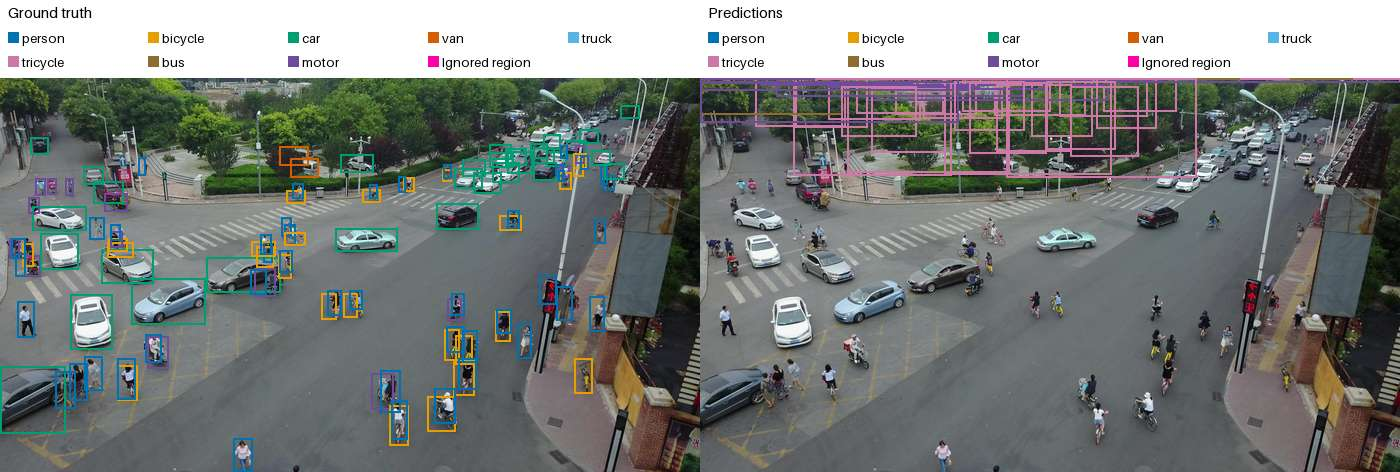

**Diagnostic only, RetinaNet with standard anchors: Tiny objects.** `val/uav0000117_02622_v/0000301`, display score ≥ 0.05.

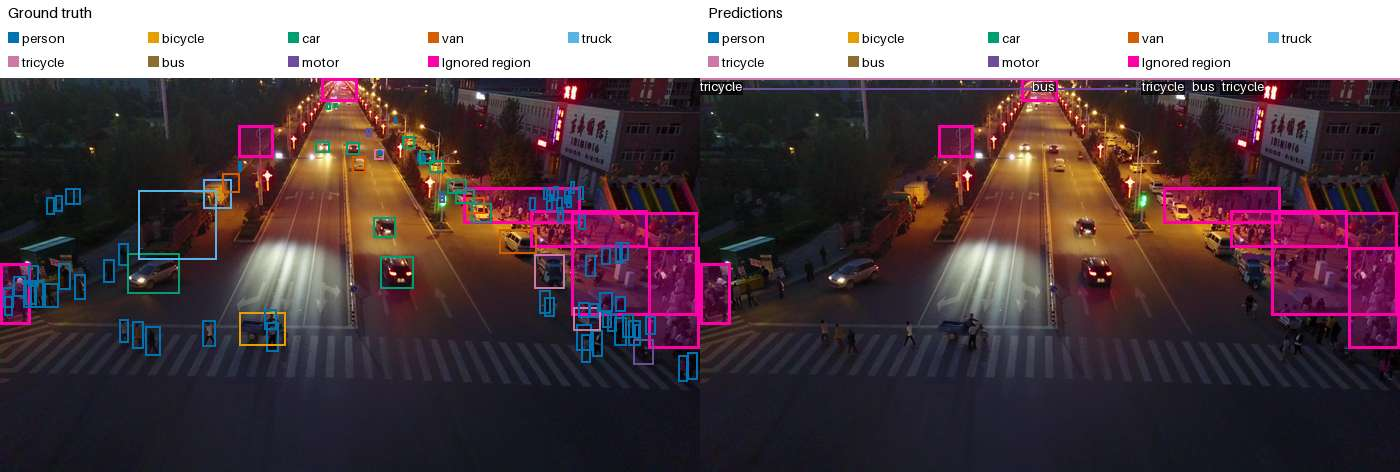

In [15]:
available_runs = list(graded_results)
gallery_mode = "Full validation"
gallery_frames = val_frames
if not available_runs and smoke_summary:
    available_runs = [descriptive_name(result["run"]) for result in smoke_summary["runs"]]
    gallery_mode = "Diagnostic only"
    gallery_frames = frames.filter(
        pl.col("image_key").is_in(smoke_summary["runs"][0]["val_image_keys"])
    )

if available_runs:
    run = available_runs[0]
    display_score_threshold = 0.3 if graded_results else 0.05
    prediction_path = (
        result_directory(EXPERIMENT_DIRECTORY, run) / "predictions.json"
        if graded_results
        else EXPERIMENT_DIRECTORY / "smoke" / f"{run}_predictions.json"
    )
    if not graded_results and not prediction_path.is_file():
        prediction_path = EXPERIMENT_DIRECTORY / "smoke" / f"{storage_id(run)}_predictions.json"
    records = json.loads(prediction_path.read_text())
    predictions_table = pl.from_dicts(
        records,
        schema={
            "image_id": pl.Int64,
            "category_id": pl.Int64,
            "bbox": pl.List(pl.Float64),
            "score": pl.Float64,
        },
    )
    pool = pl.concat(
        [
            gallery_frames.sort("target_count", descending=True).head(1),
            gallery_frames.join(val_min_areas, on="image_key")
            .sort("min_area")
            .head(1)
            .select(gallery_frames.columns),
            gallery_frames.sort("image_key").sample(
                n=min(12, gallery_frames.height), seed=TRAINING["seed"]
            ),
        ]
    ).unique("image_key", maintain_order=True)
    grouped_predictions = (
        predictions_table.filter(
            (pl.col("score") >= display_score_threshold)
            & pl.col("image_id").is_in(pool["image_id"].cast(pl.Int64).to_list())
        )
        .sort("score", descending=True)
        .group_by("image_id")
        .agg(pl.col("bbox"), pl.col("category_id"))
    )
    prediction_lookup = {
        record["image_id"]: (
            torchvision.ops.box_convert(
                torch.tensor(record["bbox"], dtype=torch.float32), "xywh", "xyxy"
            ),
            torch.tensor(record["category_id"], dtype=torch.int64),
        )
        for record in grouped_predictions.iter_rows(named=True)
    }
    minimum_area_lookup = dict(val_min_areas.rows())
    examples = []
    for row in pool.iter_rows(named=True):
        gt_boxes, gt_labels = val_dataset.targets.get(
            row["image_key"], (torch.empty(0, 4), torch.empty(0, dtype=torch.int64))
        )
        pred_boxes, pred_labels = prediction_lookup.get(
            int(row["image_id"]), (torch.empty(0, 4), torch.empty(0, dtype=torch.int64))
        )
        matched = torch.zeros(len(gt_boxes), dtype=torch.bool)
        if len(gt_boxes) and len(pred_boxes):
            overlaps = torchvision.ops.box_iou(gt_boxes, pred_boxes)
            for index, label in enumerate(pred_labels):
                eligible = (gt_labels == label) & ~matched
                quality = overlaps[:, index].masked_fill(~eligible, -1)
                best = int(quality.argmax())
                if quality[best] >= 0.5:
                    matched[best] = True
        missed = int((~matched).sum())
        examples.append(
            {
                "image_key": row["image_key"],
                "missed_gt": missed,
                "targets": len(gt_boxes),
                "min_area": minimum_area_lookup.get(row["image_key"]),
            }
        )
    candidates = pl.from_dicts(examples)
    gallery_choices = [
        ("Dense scene", candidates.sort("targets", descending=True)["image_key"][0]),
        ("Tiny objects", candidates.sort("min_area")["image_key"][0]),
    ]
    if candidates.filter(pl.col("missed_gt") > 0).height:
        gallery_choices.append(
            ("Missed-GT example", candidates.sort("missed_gt", descending=True)["image_key"][0])
        )
    else:
        display(Markdown("No missed-GT failure case was found at the stated diagnostic threshold."))
    gallery_reasons = {}
    for reason, key in gallery_choices:
        gallery_reasons.setdefault(key, []).append(reason)
    for key, reasons in gallery_reasons.items():
        row = gallery_frames.filter(pl.col("image_key") == key).row(0, named=True)
        predicted = predictions_table.filter(
            (pl.col("image_id") == int(row["image_id"]))
            & (pl.col("score") >= display_score_threshold)
        ).with_columns(
            (pl.col("category_id") - 1).alias("class_id"),
            *[
                pl.col("bbox").list.get(index).alias(name)
                for index, name in enumerate(("x", "y", "width", "height"))
            ],
        )
        image = draw_prediction_pair(
            dataset_root / row["relative_path"],
            objects.filter(pl.col("image_key") == key),
            ignored_regions.filter(pl.col("image_key") == key),
            predicted,
        )
        buffer = BytesIO()
        image.save(buffer, format="JPEG", quality=60)
        display(
            Markdown(
                f"**{gallery_mode}, {experiment_label(run)}: {', '.join(reasons)}.** `{key}`, display score ≥ {display_score_threshold}."
            )
        )
        display(DisplayImage(data=buffer.getvalue()))
else:
    display(
        Markdown(
            "Prediction examples are **Not run**. Enable the bounded GPU smoke test or an authorized graded run."
        )
    )

## 7. Comparison with two-stage detection and observations

We compare with tuned Faster R-CNN when measured results under a compatible protocol
are available. A later shared
comparison can consume `data/experiments/faster_rcnn/result.json` with `run`, `status`,
`config.validation_protocol`, `metrics.map`, `metrics.ap50`, `metrics.ap_small`,
`metrics.per_class_ap`, and the full `inference` timing dictionary. Use the common
evaluator and exactly the same validation image-key hash and maxDets for that comparison.

Until RetinaNet with standard anchors, RetinaNet with smaller anchors, and RetinaNet with DIoU regression finish, their anchor and loss effects remain hypotheses. A smoke test
establishes execution correctness, not detection quality. The three-variant smoke uses
smaller images. The separate two-update RetinaNet with standard anchors recipe probe above uses the graded resize
and batch size, with only one measured batch after warmup. Its planning estimate must
not be treated as a measured duration or an optimization recommendation.

In [16]:
comparison_path = REPOSITORY_ROOT / "data/experiments/faster_rcnn/result.json"
if comparison_path.is_file():
    two_stage = json.loads(comparison_path.read_text())
    if (
        two_stage.get("status") == "Completed"
        and two_stage.get("config", {}).get("validation_protocol") == validation_protocol
    ):
        display(pl.from_dicts([{"Model": "Faster R-CNN", **two_stage["metrics"]}]))
    else:
        display(
            Markdown(
                "Two-stage integration file exists, but its completion or evaluation protocol is incompatible."
            )
        )
else:
    display(Markdown("Two-stage comparison: **No compatible measured result supplied**."))

Two-stage comparison: **No compatible measured result supplied**.